In [1]:
!pip install -q ucimlrepo openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')

In [3]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

df.head()

Saving ecommerce_customer_transactions_sample.csv to ecommerce_customer_transactions_sample (1).csv


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,1,P9538,Notebook,5,2023-08-15 02:00:00,4.13,10253,Spain
1,1,P6710,Kitchen Accessory,5,2023-08-15 02:00:00,34.41,10253,United Kingdom
2,1,P3017,Decor Item,5,2023-08-15 02:00:00,10.60,10253,Germany
3,1,P1838,Decor Item,1,2023-08-15 02:00:00,7.85,10253,Netherlands
4,2,P1979,Mug,1,2023-10-27 17:00:00,4.97,10507,Germany


In [4]:
print(df.shape)

print(df.info())

print(df.isnull().sum())

print(df.describe())

print("Duplicate values:", df.duplicated().sum())

(27061, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27061 entries, 0 to 27060
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    27061 non-null  int64  
 1   StockCode    27061 non-null  object 
 2   Description  27061 non-null  object 
 3   Quantity     27061 non-null  int64  
 4   InvoiceDate  27061 non-null  object 
 5   UnitPrice    27061 non-null  float64
 6   CustomerID   27061 non-null  int64  
 7   Country      27061 non-null  object 
dtypes: float64(1), int64(3), object(4)
memory usage: 1.7+ MB
None
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
          InvoiceNo      Quantity     UnitPrice    CustomerID
count  27061.000000  27061.000000  27061.000000  27061.000000
mean    4489.815417      4.009091      9.443872  10600.075940
std     2601.929646      2.012248      7.785949    345.3462

In [5]:
df = df.dropna(subset=['CustomerID'])

df = df.drop_duplicates()

df['CustomerID'] = df['CustomerID'].astype(int).astype(str)

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

df = df[df['Quantity'] > 0]

df = df[df['UnitPrice'] > 0]

print("After cleaning:", df.shape)

After cleaning: (27061, 8)


In [6]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,1,P9538,Notebook,5,2023-08-15 02:00:00,4.13,10253,Spain,20.65
1,1,P6710,Kitchen Accessory,5,2023-08-15 02:00:00,34.41,10253,United Kingdom,172.05
2,1,P3017,Decor Item,5,2023-08-15 02:00:00,10.60,10253,Germany,53.00
3,1,P1838,Decor Item,1,2023-08-15 02:00:00,7.85,10253,Netherlands,7.85
4,2,P1979,Mug,1,2023-10-27 17:00:00,4.97,10507,Germany,4.97


In [7]:
today = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (today - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
10001,29,7,1007.22
10002,18,6,861.70
10003,8,7,687.84
10004,30,14,1736.53
10005,230,1,98.48


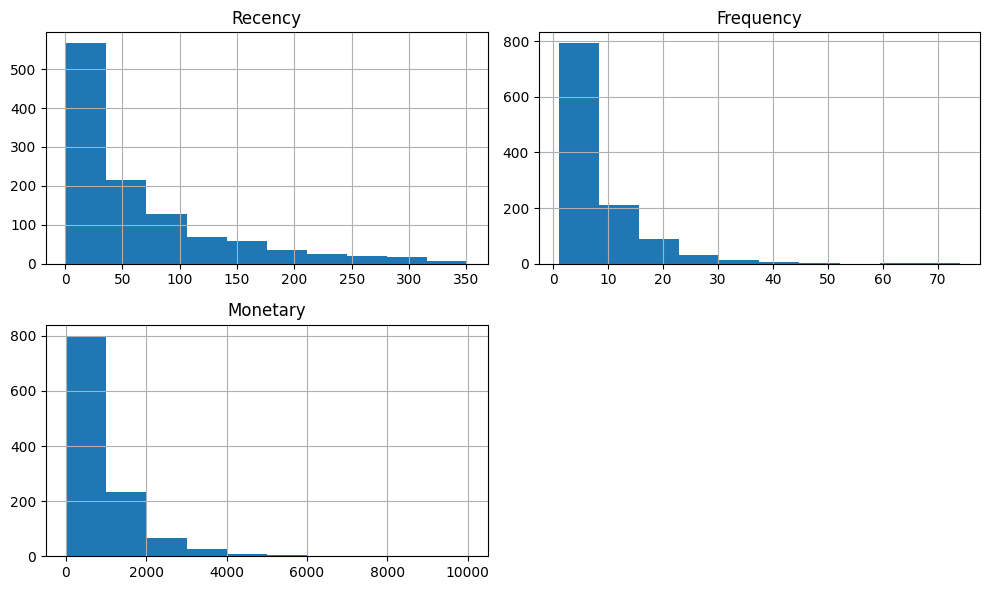

In [8]:
rfm.hist(figsize=(10, 6))

plt.tight_layout()
plt.show()

In [9]:
rfm = np.log1p(rfm)

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm)

print("Data scaling completed")

Data scaling completed


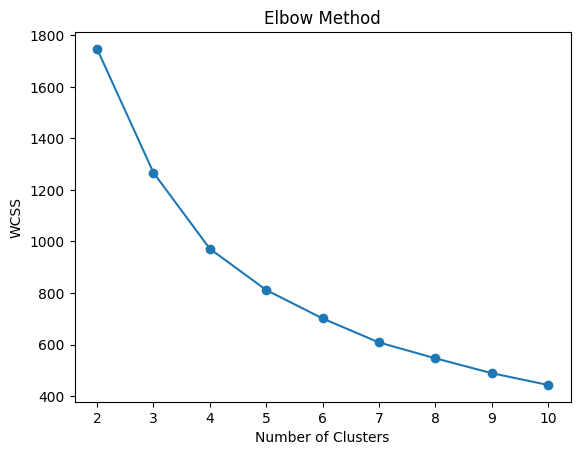

In [10]:
wcss = []

for i in range(2, 11):

    km = KMeans(n_clusters=i, random_state=42, n_init=10)

    km.fit(rfm_scaled)

    wcss.append(km.inertia_)

plt.plot(range(2, 11), wcss, marker='o')

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [11]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['KMeans'] = km.fit_predict(rfm_scaled)

print(rfm['KMeans'].value_counts())

KMeans
0    409
2    266
1    244
3    224
Name: count, dtype: int64


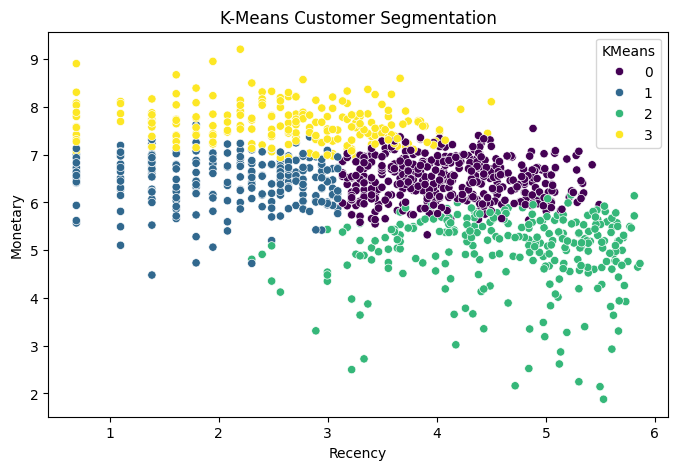

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['Recency'],
    y=rfm['Monetary'],
    hue=rfm['KMeans'],
    palette='viridis'
)

plt.title("K-Means Customer Segmentation")

plt.show()

In [13]:
db = DBSCAN(eps=0.8, min_samples=10)

rfm['DBSCAN'] = db.fit_predict(rfm_scaled)

print(rfm['DBSCAN'].value_counts())

DBSCAN
 0    1138
-1       5
Name: count, dtype: int64


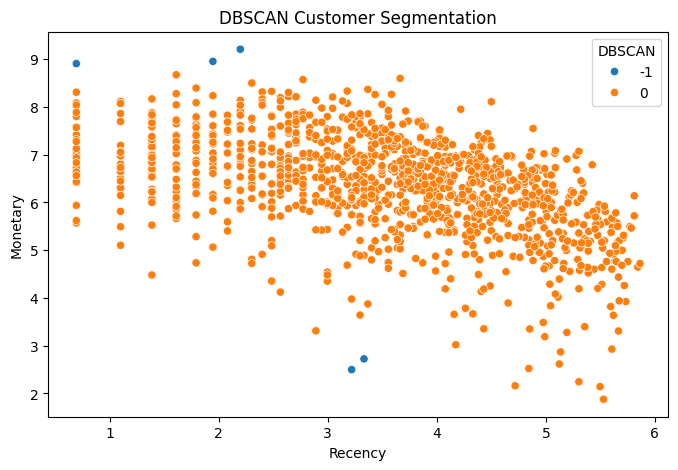

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['Recency'],
    y=rfm['Monetary'],
    hue=rfm['DBSCAN'],
    palette='tab10'
)

plt.title("DBSCAN Customer Segmentation")

plt.show()

In [15]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(rfm_scaled)

rfm['PCA1'] = pca_data[:, 0]
rfm['PCA2'] = pca_data[:, 1]

print("Explained variance:", pca.explained_variance_ratio_.sum())

Explained variance: 0.9674350050121476


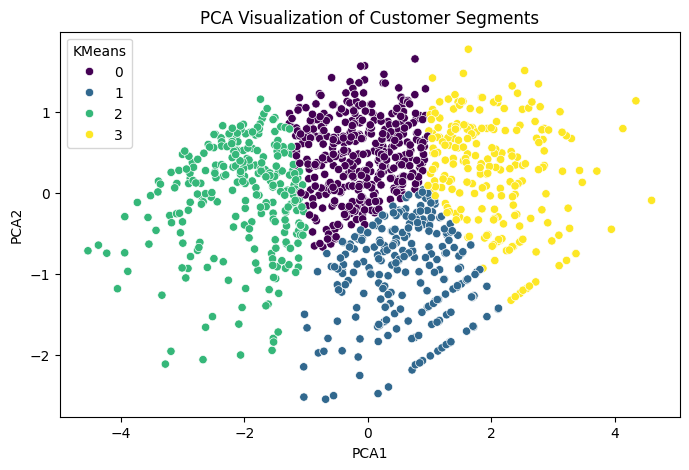

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['PCA1'],
    y=rfm['PCA2'],
    hue=rfm['KMeans'],
    palette='viridis'
)

plt.title("PCA Visualization of Customer Segments")

plt.show()

In [17]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

tsne_data = tsne.fit_transform(rfm_scaled)

rfm['TSNE1'] = tsne_data[:, 0]
rfm['TSNE2'] = tsne_data[:, 1]

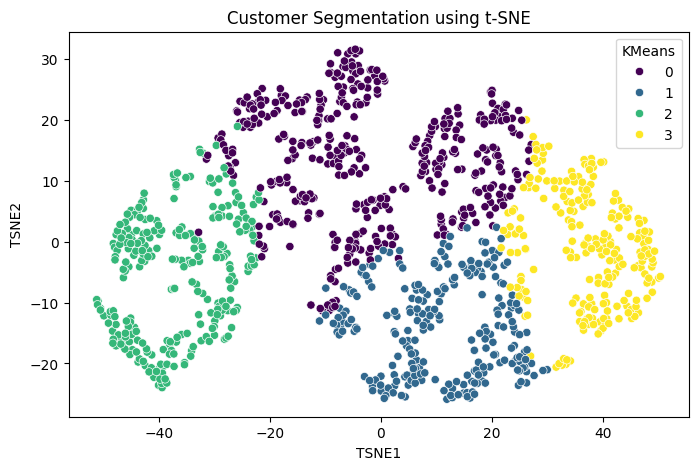

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['TSNE1'],
    y=rfm['TSNE2'],
    hue=rfm['KMeans'],
    palette='viridis'
)

plt.title("Customer Segmentation using t-SNE")

plt.show()

In [19]:
result = rfm.groupby('KMeans').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
})

result['Customers'] = rfm.groupby('KMeans').size()

print(result)

         Recency  Frequency  Monetary  Customers
KMeans                                          
0       4.115907   1.934249  6.483038        409
1       2.098516   1.924652  6.460732        244
2       4.680737   1.057382  4.970196        266
3       2.627184   2.946588  7.636234        224


In [20]:
score = silhouette_score(
    rfm_scaled,
    rfm['KMeans'],
    sample_size=min(10000, len(rfm)),
    random_state=42
)

print("K-Means Silhouette Score:", score)

K-Means Silhouette Score: 0.34861178720545355


In [21]:
for i in result.index:

    print("\nCluster:", i)

    if result.loc[i, 'Monetary'] > result['Monetary'].median() and result.loc[i, 'Frequency'] > result['Frequency'].median():

        print("Persona: High Value Customers")
        print("Strategy: Give loyalty rewards and exclusive offers")

    elif result.loc[i, 'Recency'] > result['Recency'].median():

        print("Persona: At Risk Customers")
        print("Strategy: Send discount coupons and reminder emails")

    elif result.loc[i, 'Frequency'] > result['Frequency'].median():

        print("Persona: Regular Customers")
        print("Strategy: Provide membership and referral benefits")

    else:

        print("Persona: Potential Customers")
        print("Strategy: Provide special offers to increase purchases")


Cluster: 0
Persona: High Value Customers
Strategy: Give loyalty rewards and exclusive offers

Cluster: 1
Persona: Potential Customers
Strategy: Provide special offers to increase purchases

Cluster: 2
Persona: At Risk Customers
Strategy: Send discount coupons and reminder emails

Cluster: 3
Persona: High Value Customers
Strategy: Give loyalty rewards and exclusive offers


In [22]:
rfm.to_csv("Customer_Segmentation_Result.csv")

from google.colab import files

files.download("Customer_Segmentation_Result.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>